<a href="https://colab.research.google.com/github/ManuelRomero2025/Programaci-nPython20254/blob/colab-estadistica/Colab_Pandas_Analisis_Exploratorio_Estadistica_Sueno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

## 1. Carga de la base de datos en Google Colab

Ejecute la siguiente celda y seleccione el archivo **Sleep_health_and_lifestyle_dataset.csv** de su computador. No es obligatorio conectar Google Drive.

In [ ]:
# Asegúrate de haber montado Google Drive previamente
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Leer el archivo desde Drive
df = pd.read_csv('/content/drive/MyDrive/LosLibertadores20252/Sleep_health_and_lifestyle_dataset.csv')

In [ ]:
# Vista inicial de la estructura
df.head()


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
df.columns

Index(['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration',
       'Quality of Sleep', 'Physical Activity Level', 'Stress Level',
       'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps',
       'Sleep Disorder'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [ ]:
# Eliminar duplicados
df.drop_duplicates()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [ ]:
df.nunique()

,0
Person ID,374
Gender,2
Age,31
Occupation,11
Sleep Duration,27
Quality of Sleep,6
Physical Activity Level,16
Stress Level,6
BMI Category,4
Blood Pressure,25


In [ ]:
#Quitar espacios en nombres de columnas.
df.columns.str.strip()

Index(['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration',
       'Quality of Sleep', 'Physical Activity Level', 'Stress Level',
       'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps',
       'Sleep Disorder'],
      dtype='object')

In [ ]:
# Limpiar espacios de columnas EN EL MISMO DATAFRAME
df.columns = df.columns.str.strip().str.replace(' ', '_')

# Verifica que se aplicó correctamente
print(df.columns.tolist())  # Debe mostrar nombres con "_"

# Visualiza el resultado con los nuevos nombres
df.head()


['Person_ID', 'Gender', 'Age', 'Occupation', 'Sleep_Duration', 'Quality_of_Sleep', 'Physical_Activity_Level', 'Stress_Level', 'BMI_Category', 'Blood_Pressure', 'Heart_Rate', 'Daily_Steps', 'Sleep_Disorder']


,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
df['Gender'] = df['Gender'].astype(str)

In [ ]:
df.shape

(374, 13)

In [ ]:
df.isnull().sum()

,0
Person_ID,0
Gender,0
Age,0
Occupation,0
Sleep_Duration,0
Quality_of_Sleep,0
Physical_Activity_Level,0
Stress_Level,0
BMI_Category,0
Blood_Pressure,0


In [ ]:
# Eliminar filas que contengan al menos un NA
df2 = df.dropna()

In [ ]:
# Vista inicial de la estructura
df2.head()


,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea


In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 155 entries, 3 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person_ID                155 non-null    int64  
 1   Gender                   155 non-null    object 
 2   Age                      155 non-null    int64  
 3   Occupation               155 non-null    object 
 4   Sleep_Duration           155 non-null    float64
 5   Quality_of_Sleep         155 non-null    int64  
 6   Physical_Activity_Level  155 non-null    int64  
 7   Stress_Level             155 non-null    int64  
 8   BMI_Category             155 non-null    object 
 9   Blood_Pressure           155 non-null    object 
 10  Heart_Rate               155 non-null    int64  
 11  Daily_Steps              155 non-null    int64  
 12  Sleep_Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 17.0+ KB


In [ ]:
df2.shape


(155, 13)

In [ ]:
#rempalzar todos los NA's con...
df.fillna("No se tiene información")

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,No se tiene información
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,No se tiene información
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,No se tiene información
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [ ]:
df2.describe()

,Person_ID,Age,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,Heart_Rate,Daily_Steps
count,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000
mean,244.761290,46.632258,6.812258,6.870968,60.896774,5.767742,71.787097,6765.806452
std,91.282997,7.839311,0.773534,1.337325,20.634158,1.946757,5.187381,1893.921881
min,4.000000,28.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,199.500000,43.000000,6.300000,6.000000,45.000000,4.000000,68.000000,6000.000000
50%,255.000000,45.000000,6.500000,7.000000,45.000000,7.000000,72.000000,6000.000000
75%,304.500000,51.000000,7.400000,8.000000,75.000000,7.000000,75.000000,7000.000000
max,374.000000,59.000000,8.300000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [ ]:
#media
df2["Age"].mean()

np.float64(46.63225806451613)

In [ ]:
#mediana
df2["Age"].median()

45.0

In [ ]:
import statistics

In [ ]:
#moda
statistics.mode(df2["Age"])

44

In [ ]:
df2.describe(include='object')

,Gender,Occupation,BMI_Category,Blood_Pressure,Sleep_Disorder
count,155,155,155,155,155
unique,2,10,4,14,2
top,Female,Nurse,Overweight,140/95,Sleep Apnea
freq,103,64,129,60,78


In [ ]:
df2.describe(include='all')

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
count,155.000000,155,155.000000,155,155.000000,155.000000,155.000000,155.000000,155,155,155.000000,155.000000,155
unique,NaN,2,NaN,10,NaN,NaN,NaN,NaN,4,14,NaN,NaN,2
top,NaN,Female,NaN,Nurse,NaN,NaN,NaN,NaN,Overweight,140/95,NaN,NaN,Sleep Apnea
freq,NaN,103,NaN,64,NaN,NaN,NaN,NaN,129,60,NaN,NaN,78
mean,244.761290,NaN,46.632258,NaN,6.812258,6.870968,60.896774,5.767742,NaN,NaN,71.787097,6765.806452,NaN
std,91.282997,NaN,7.839311,NaN,0.773534,1.337325,20.634158,1.946757,NaN,NaN,5.187381,1893.921881,NaN
min,4.000000,NaN,28.000000,NaN,5.800000,4.000000,30.000000,3.000000,NaN,NaN,65.000000,3000.000000,NaN
25%,199.500000,NaN,43.000000,NaN,6.300000,6.000000,45.000000,4.000000,NaN,NaN,68.000000,6000.000000,NaN
50%,255.000000,NaN,45.000000,NaN,6.500000,7.000000,45.000000,7.000000,NaN,NaN,72.000000,6000.000000,NaN
75%,304.500000,NaN,51.000000,NaN,7.400000,8.000000,75.000000,7.000000,NaN,NaN,75.000000,7000.000000,NaN


In [ ]:
#CUARTILES
np.percentile(df2['Age'], [25, 50, 75])

array([43., 45., 51.])

In [ ]:
q3 = df["Sleep_Duration"].quantile(0.75)
df[df["Sleep_Duration"] > q3]

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
25,26,Male,30,Doctor,7.9,7,75,6,Normal,120/80,70,8000,NaN
27,28,Male,30,Doctor,7.9,7,75,6,Normal,120/80,70,8000,NaN
28,29,Male,30,Doctor,7.9,7,75,6,Normal,120/80,70,8000,NaN
29,30,Male,30,Doctor,7.9,7,75,6,Normal,120/80,70,8000,NaN
32,33,Female,31,Nurse,7.9,8,75,4,Normal Weight,117/76,69,6800,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [ ]:
import numpy as np

def boxplot_stats(data):
    x = np.array(data)
    x = x[~np.isnan(x)]  # Eliminar NaN si los hay

    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1

    lower_whisker = q1 - 1.5 * iqr
    upper_whisker = q3 + 1.5 * iqr

    # Datos sin outliers para definir los bigotes
    no_outliers = x[(x >= lower_whisker) & (x <= upper_whisker)]
    stats = [no_outliers.min(), q1, np.median(x), q3, no_outliers.max()]
    outliers = x[(x < lower_whisker) | (x > upper_whisker)]

    return {
        'stats': stats,
        'outliers': outliers,
        'n': len(x)
    }


In [ ]:
resultado = boxplot_stats(df2['Age'])
print("Valores del boxplot:", resultado['stats'])
print("Outliers:", resultado['outliers'])

Valores del boxplot: [np.int64(31), np.float64(43.0), np.float64(45.0), np.float64(51.0), np.int64(59)]
Outliers: [28 28 28 29 29 29 29 30 30]


In [ ]:
df2[df2['Age']<=30]

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea
17,18,Male,29,Doctor,6.0,6,30,8,Normal,120/80,70,8000,Sleep Apnea
18,19,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Insomnia
30,31,Female,30,Nurse,6.4,5,35,7,Normal Weight,130/86,78,4100,Sleep Apnea
31,32,Female,30,Nurse,6.4,5,35,7,Normal Weight,130/86,78,4100,Insomnia


In [ ]:
df2[df2['Age']>30]

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
49,50,Male,31,Doctor,7.7,7,75,6,Normal,120/80,70,8000,Sleep Apnea
67,68,Male,33,Doctor,6.0,6,30,8,Normal,125/80,72,5000,Insomnia
80,81,Female,34,Scientist,5.8,4,32,8,Overweight,131/86,81,5200,Sleep Apnea
81,82,Female,34,Scientist,5.8,4,32,8,Overweight,131/86,81,5200,Sleep Apnea
93,94,Male,35,Lawyer,7.4,7,60,5,Obese,135/88,84,3300,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [ ]:
df2[df2['Heart_Rate']==0]

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder


In [ ]:
# 1. Asegúrate de que df3 es una copia real del DataFrame original
df3 = df2.copy()  # Esto elimina

# 2. Separar la columna 'Blood_Pressure' en dos columnas nuevas
df3[['Systolic', 'Diastolic']] = df3['Blood_Pressure'].str.split('/', expand=True)

# 3. Convertir ambas columnas a tipo numérico (int o float)
df3['Systolic'] = pd.to_numeric(df3['Systolic'], errors='coerce')
df3['Diastolic'] = pd.to_numeric(df3['Diastolic'], errors='coerce')


In [ ]:
df3[['Blood_Pressure', 'Systolic', 'Diastolic']].head()

,Blood_Pressure,Systolic,Diastolic
3,140/90,140,90
4,140/90,140,90
5,140/90,140,90
6,140/90,140,90
16,132/87,132,87


In [ ]:
df3.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia,140,90
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia,140,90
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea,132,87


In [ ]:
# Personas con categoría de IMC "Obese"
df_obese = df3[df3['BMI_Category'] == 'Obese']
df_obese.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia,140,90
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia,140,90
93,94,Male,35,Lawyer,7.4,7,60,5,Obese,135/88,84,3300,Sleep Apnea,135,88


In [ ]:
# Hombres con apnea del sueño
df_apnea = df3.query("Gender == 'Male' and Sleep_Disorder == 'Sleep Apnea'")
df_apnea.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
17,18,Male,29,Doctor,6.0,6,30,8,Normal,120/80,70,8000,Sleep Apnea,120,80
49,50,Male,31,Doctor,7.7,7,75,6,Normal,120/80,70,8000,Sleep Apnea,120,80
93,94,Male,35,Lawyer,7.4,7,60,5,Obese,135/88,84,3300,Sleep Apnea,135,88


In [ ]:
# Personas con categoría de IMC "Obese"
df_obese = df2[df2['BMI_Category'] == 'Normal']
df_obese.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
17,18,Male,29,Doctor,6.0,6,30,8,Normal,120/80,70,8000,Sleep Apnea
49,50,Male,31,Doctor,7.7,7,75,6,Normal,120/80,70,8000,Sleep Apnea
67,68,Male,33,Doctor,6.0,6,30,8,Normal,125/80,72,5000,Insomnia
94,95,Female,36,Accountant,7.2,8,60,4,Normal,115/75,68,7000,Insomnia
104,105,Female,36,Teacher,7.2,8,60,4,Normal,115/75,68,7000,Sleep Apnea


In [ ]:
# Mujeres con presión sistólica mayor a 130
df_high = df3[(df3['Gender'] == 'Female') & (df3['Systolic'] > 130)]
df_high.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea,132,87
18,19,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Insomnia,132,87
80,81,Female,34,Scientist,5.8,4,32,8,Overweight,131/86,81,5200,Sleep Apnea,131,86
81,82,Female,34,Scientist,5.8,4,32,8,Overweight,131/86,81,5200,Sleep Apnea,131,86
145,146,Female,38,Lawyer,7.4,7,60,5,Obese,135/88,84,3300,Sleep Apnea,135,88


In [ ]:
# Hombres con presión sistólica mayor a 130
df_high1 = df3[(df3['Gender'] == 'Male') | (df3['Systolic'] > 130)]
df_high1.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia,140,90
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia,140,90
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea,132,87


In [ ]:
# Mujeres con presión sistólica mayor a 130
df_high2 = df3[(df3['Gender'] == 'Female') & (df3['Systolic'] > 130) & (df3['Diastolic'] > 80)]
df_high2.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea,132,87
18,19,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Insomnia,132,87
80,81,Female,34,Scientist,5.8,4,32,8,Overweight,131/86,81,5200,Sleep Apnea,131,86
81,82,Female,34,Scientist,5.8,4,32,8,Overweight,131/86,81,5200,Sleep Apnea,131,86
145,146,Female,38,Lawyer,7.4,7,60,5,Obese,135/88,84,3300,Sleep Apnea,135,88


In [ ]:
maxage=np.max(df3['Age'])
minage=np.min(df3['Age'])
print(maxage)
print(minage)

59
28


In [ ]:
# Frecuencia absoluta de la columna 'BMI_Category'
freq_abs = df2['BMI_Category'].value_counts()
print(freq_abs)

BMI_Category
Overweight       129
Normal            12
Obese             10
Normal Weight      4
Name: count, dtype: int64


In [ ]:
# Frecuencia relativa (proporciones)
freq_rel = df2['BMI_Category'].value_counts(normalize=True)
print(freq_rel)


BMI_Category
Overweight       0.832258
Normal           0.077419
Obese            0.064516
Normal Weight    0.025806
Name: proportion, dtype: float64


In [ ]:
# Combinar frecuencia absoluta y relativa en un DataFrame
tabla_frecuencia = pd.DataFrame({
    'Frecuencia': df2['BMI_Category'].value_counts(),
    'Porcentaje (%)': df2['BMI_Category'].value_counts(normalize=True) * 100
})
print(tabla_frecuencia)


               Frecuencia  Porcentaje (%)
BMI_Category                             
Overweight            129       83.225806
Normal                 12        7.741935
Obese                  10        6.451613
Normal Weight           4        2.580645


# **Tabla de distribución de frecuencia**

In [ ]:
# Supongamos que trabajamos sobre la columna 'Systolic' ya convertida a numérico
# Elimina valores nulos si existen
data = df3['Systolic'].dropna()

clase=1+3.33*np.log10(len(data))
clase=int(clase)
print(clase)

# Crear intervalos con pd.cut()
#right=False: define los intervalos como cerrados a la izquierda y abiertos a la derecha: [a, b)
intervalos = pd.cut(data, bins=6, right=False)  # Puedes cambiar el número de bins según tu caso

# Contar frecuencia por intervalo
frecuencia = intervalos.value_counts().sort_index()
print(frecuencia)

8
Systolic
[115.0, 119.5)       2
[119.5, 124.0)       2
[124.0, 128.5)       2
[128.5, 133.0)      54
[133.0, 137.5)      27
[137.5, 142.027)    68
Name: count, dtype: int64


In [ ]:
# Crear 4 cuartiles
cuartiles = pd.qcut(df3['Age'], q=4) #Número de grupos o lista de percentiles (ej: 4 = cuartiles)
print(cuartiles.value_counts().sort_index())

Age
(27.999, 43.0]    45
(43.0, 45.0]      39
(45.0, 51.0]      34
(51.0, 59.0]      37
Name: count, dtype: int64


In [ ]:
df3['Age_Quartile'] = pd.qcut(df3['Age'],
                              q=4,
                              labels=["Q1", "Q2", "Q3", "Q4"])
print(df3['Age_Quartile'].value_counts().sort_index())


Age_Quartile
Q1    45
Q2    39
Q3    34
Q4    37
Name: count, dtype: int64


# **Calcular frecuencia acumulada y relativa**

In [ ]:
# Frecuencia absoluta
fi = frecuencia

# Frecuencia acumulada
Fi = fi.cumsum()

# Frecuencia relativa (%)
fr = (fi / fi.sum()) * 100

tabla_distribucion = pd.DataFrame({
    'Intervalo': fi.index.astype(str),
    'Frecuencia (fi)': fi.values,
    'Frecuencia acumulada (Fi)': Fi.values,
    'Frecuencia relativa (%)': fr.round(2).values
})
print(tabla_distribucion)



          Intervalo  Frecuencia (fi)  Frecuencia acumulada (Fi)  \
0    [115.0, 119.5)                2                          2   
1    [119.5, 124.0)                2                          4   
2    [124.0, 128.5)                2                          6   
3    [128.5, 133.0)               54                         60   
4    [133.0, 137.5)               27                         87   
5  [137.5, 142.027)               68                        155   

   Frecuencia relativa (%)  
0                     1.29  
1                     1.29  
2                     1.29  
3                    34.84  
4                    17.42  
5                    43.87  


In [ ]:
dataAge = df3["Age"].dropna()
df3["Age_Ctv"] = pd.cut(dataAge,
                        bins=3,
                        labels=['Joven', 'Adulto', 'Viejo'])
df3.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder,Systolic,Diastolic,Age_Quartile,Age_Ctv
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90,Q1,Joven
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea,140,90,Q1,Joven
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia,140,90,Q1,Joven
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia,140,90,Q1,Joven
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea,132,87,Q1,Joven


In [ ]:
df3["Age_Ctv"].value_counts()

,count
Age_Ctv,
Viejo,68
Adulto,67
Joven,20


In [ ]:
df3.pivot_table("Age", #resumir la variable Age (edad) usando el promedio (por defecto).
                index="Gender",
                columns="Age_Ctv",
                margins=True) #promedios globales (totales marginales).

/tmp/ipykernel_2356/1489243054.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df3.pivot_table("Age", #resumir la variable Age (edad) usando el promedio (por defecto).


Age_Ctv,Joven,Adulto,Viejo,All
Gender,,,,
Female,32.888889,44.285714,53.787879,49.378641
Male,31.909091,43.410256,49.000000,41.192308
All,32.350000,43.776119,53.647059,46.632258


In [ ]:
df3.pivot_table(index="Gender",
                columns="Age_Ctv",
                aggfunc={'Age':"mean"}) #aggfunc='median'`, `'count'`, `'sum'`, etc.

/tmp/ipykernel_2356/2925334354.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df3.pivot_table(index="Gender",


Age                      
Age_Ctv      Joven     Adulto      Viejo
Gender                                  
Female   32.888889  44.285714  53.787879
Male     31.909091  43.410256  49.000000

In [ ]:
df3.pivot_table(index="Gender",
                columns="Age_Ctv",
                aggfunc={'Age':sum, "Sleep_Duration":'mean'})

/tmp/ipykernel_2356/817228287.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df3.pivot_table(index="Gender",
/tmp/ipykernel_2356/817228287.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  df3.pivot_table(index="Gender",


Age              Sleep_Duration                    
Age_Ctv Joven Adulto Viejo          Joven    Adulto     Viejo
Gender                                                       
Female    296   1240  3550       6.577778  6.585714  7.069697
Male      351   1693    98       6.490909  6.617949  8.100000

# **Dividir un DataFrame en grupos**

In [ ]:
print(df.groupby('Gender').groups)

{'Female': [16, 18, 30, 31, 32, 68, 69, 80, 81, 85, 94, 95, 96, 97, 98, 99, 100, 101, 102, 104, 106, 110, 112, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 127, 130, 133, 136, 138, 140, 142, 143, 145, 148, 149, 150, 161, 162, 184, 185, 186, 188, 190, 220, 224, 226, 228, 230, 232, 234, 237, 240, 243, 245, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 265, 267, 268, 269, 270, 271, 272, 273, 274, 275, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, ...], 'Male': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 103, 105, 107, 108, 109, 111, 113, 126, 128, 129, 131, 132, 134, 135, 137, 139, ...]}


In [ ]:
group_dict = df.groupby('Gender').groups

print("Índices de las mujeres:", group_dict['Female'])
print("Índices de los hombres:", group_dict['Male'])


Índices de las mujeres: Index([ 16,  18,  30,  31,  32,  68,  69,  80,  81,  85,
       ...
       364, 365, 366, 367, 368, 369, 370, 371, 372, 373],
      dtype='int64', length=185)
Índices de los hombres: Index([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,
       ...
       242, 244, 246, 247, 248, 249, 264, 266, 276, 277],
      dtype='int64', length=189)


In [ ]:
# Crear subconjuntos por grupo
female_rows = df.loc[group_dict['Female']]
male_rows = df.loc[group_dict['Male']]


In [ ]:
female_rows.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea
18,19,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Insomnia
30,31,Female,30,Nurse,6.4,5,35,7,Normal Weight,130/86,78,4100,Sleep Apnea
31,32,Female,30,Nurse,6.4,5,35,7,Normal Weight,130/86,78,4100,Insomnia
32,33,Female,31,Nurse,7.9,8,75,4,Normal Weight,117/76,69,6800,NaN


In [ ]:
male_rows.head()

,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
# Promedio de edad por género
df.groupby('Gender')['Age'].mean()


,Age
Gender,
Female,47.405405
Male,37.074074


In [ ]:
df3.groupby(['BMI_Category', 'Gender'])['Systolic'].mean()

BMI_Category   Gender
Normal         Female    118.333333
               Male      127.222222
Normal Weight  Female    131.000000
Obese          Female    135.000000
               Male      139.666667
Overweight     Female    137.652632
               Male      130.000000
Name: Systolic, dtype: float64

In [ ]:
df3.groupby('Gender')['Systolic'].agg(['mean', 'min', 'max', 'count'])


,mean,min,max,count
Gender,,,,
Female,136.805825,115,140,103
Male,131.192308,120,142,52


In [ ]:
print(df.groupby('Gender').get_group('Male'))

     Person_ID Gender  Age            Occupation  Sleep_Duration  \
0            1   Male   27     Software Engineer             6.1   
1            2   Male   28                Doctor             6.2   
2            3   Male   28                Doctor             6.2   
3            4   Male   28  Sales Representative             5.9   
4            5   Male   28  Sales Representative             5.9   
..         ...    ...  ...                   ...             ...   
249        250   Male   44           Salesperson             6.5   
264        265   Male   48                Doctor             7.3   
266        267   Male   48                Doctor             7.3   
276        277   Male   49                Doctor             8.1   
277        278   Male   49                Doctor             8.1   

     Quality_of_Sleep  Physical_Activity_Level  Stress_Level BMI_Category  \
0                   6                       42             6   Overweight   
1                   6        

# **Reestructurar un DataFrame**

In [ ]:
datos = {"Departamentos":["Cundinamarca", "Bogotá", "Boyaca", "Caldas"],
                  "Edad":[18, 22, 20, 30],
             "Score Uno":[20, 30, 40,50],
             "Score Dos":[28, 65, 45, 60],
            "Score Tres":[65, 64, 49, 45]}
df4 = pd.DataFrame(datos)
print(df4)

  Departamentos  Edad  Score Uno  Score Dos  Score Tres
0  Cundinamarca    18         20         28          65
1        Bogotá    22         30         65          64
2        Boyaca    20         40         45          49
3        Caldas    30         50         60          45


## **Convertir un DataFrame a formato largo**

In [ ]:
# Usar df4, que sí contiene Departamentos, Edad y las puntuaciones
# Pasar de formato ancho a formato largo
df5 = df4.melt(id_vars=["Departamentos", "Edad"],
               var_name="Pruebas", value_name="Scores")
print(df5)

   Departamentos  Edad     Pruebas  Scores
0   Cundinamarca    18   Score Uno      20
1         Bogotá    22   Score Uno      30
2         Boyaca    20   Score Uno      40
3         Caldas    30   Score Uno      50
4   Cundinamarca    18   Score Dos      28
5         Bogotá    22   Score Dos      65
6         Boyaca    20   Score Dos      45
7         Caldas    30   Score Dos      60
8   Cundinamarca    18  Score Tres      65
9         Bogotá    22  Score Tres      64
10        Boyaca    20  Score Tres      49
11        Caldas    30  Score Tres      45


## **Convertir un DataFrame a formato ancho**

In [ ]:
print(df5.pivot(index="Departamentos", columns="Pruebas", values="Scores"))

Pruebas        Score Dos  Score Tres  Score Uno
Departamentos                                  
Bogotá                65          64         30
Boyaca                45          49         40
Caldas                60          45         50
Cundinamarca          28          65         20


---
# 2. Módulo adicional: análisis exploratorio y estadística descriptiva

**Objetivo:** aprender, de manera progresiva, a describir, limpiar, resumir, visualizar e interpretar una base de datos de salud y estilo de vida. Se parte de preguntas sencillas y se avanza a asociaciones entre variables.

**Importante:** esta sección utiliza una copia nueva de `df`, llamada `salud`, para **conservar los 374 registros**. En las celdas anteriores se creó `df2 = df.dropna()`, que excluye los registros sin valor en `Sleep_Disorder`. Esos valores faltantes no se deben interpretar automáticamente como personas sin trastornos del sueño.

Las gráficas muestran asociaciones descriptivas, no relaciones de causa y efecto.

## Nivel básico — Conocer la información
### 2.1. Estructura y tipo de cada variable

**Pregunta:** ¿cuántas personas y variables hay? ¿Cuáles son numéricas y cuáles son categóricas? `shape` informa dimensiones y `dtypes` el tipo de cada columna.

In [ ]:
salud = df.copy()
print("Filas y columnas:", salud.shape)
print("Nombres de las variables:", salud.columns.tolist())
print("Tipos de datos:")
print(salud.dtypes)

Filas y columnas: (374, 13)
Nombres de las variables: ['Person_ID', 'Gender', 'Age', 'Occupation', 'Sleep_Duration', 'Quality_of_Sleep', 'Physical_Activity_Level', 'Stress_Level', 'BMI_Category', 'Blood_Pressure', 'Heart_Rate', 'Daily_Steps', 'Sleep_Disorder']
Tipos de datos:
Person_ID                    int64
Gender                      object
Age                          int64
Occupation                  object
Sleep_Duration             float64
Quality_of_Sleep             int64
Physical_Activity_Level      int64
Stress_Level                 int64
BMI_Category                object
Blood_Pressure              object
Heart_Rate                   int64
Daily_Steps                  int64
Sleep_Disorder              object
dtype: object


### 2.2. Primera exploración

`head()` muestra registros iniciales; `sample()` selecciona filas al azar. Un identificador como `Person_ID` **no es una variable para promediar**, aunque esté almacenado como número.

In [ ]:
print("Primeras cinco personas:")
display(salud.head())
print("Cinco registros aleatorios:")
display(salud.sample(5, random_state=25))

Primeras cinco personas:


,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Cinco registros aleatorios:


,Person_ID,Gender,Age,Occupation,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,BMI_Category,Blood_Pressure,Heart_Rate,Daily_Steps,Sleep_Disorder
326,327,Female,53,Engineer,8.3,9,30,3,Normal,125/80,65,5000,NaN
297,298,Female,50,Nurse,6.1,6,90,8,Overweight,140/95,75,10000,Sleep Apnea
45,46,Male,31,Doctor,7.8,7,75,6,Normal,120/80,70,8000,NaN
56,57,Male,32,Doctor,7.7,7,75,6,Normal,120/80,70,8000,NaN
84,85,Male,35,Software Engineer,7.5,8,60,5,Normal Weight,120/80,70,8000,NaN


### 2.3. Valores faltantes y registros duplicados

**Pregunta:** ¿hay información incompleta? `isna().sum()` cuenta los vacíos. Antes de eliminar duplicados, se debe determinar si son registros repetidos o diferentes personas con características similares.

In [ ]:
faltantes = pd.DataFrame({
    "Faltantes": salud.isna().sum(),
    "Porcentaje (%)": (salud.isna().mean()*100).round(2)
})
display(faltantes)
print("Filas exactamente repetidas:", salud.duplicated().sum())
print("Identificadores repetidos:", salud["Person_ID"].duplicated().sum())

,Faltantes,Porcentaje (%)
Person_ID,0,0.00
Gender,0,0.00
Age,0,0.00
Occupation,0,0.00
Sleep_Duration,0,0.00
Quality_of_Sleep,0,0.00
Physical_Activity_Level,0,0.00
Stress_Level,0,0.00
BMI_Category,0,0.00
Blood_Pressure,0,0.00


Filas exactamente repetidas: 0
Identificadores repetidos: 0


### 2.4. Selección de variables para el estudio

Se estudiarán principalmente la **edad**, la **duración del sueño** y el **nivel de estrés**, en vez de calcular muchos resultados sin interpretación. También se emplearán `Gender`, `BMI_Category` y `Sleep_Disorder` como variables de agrupación.

In [ ]:
variables = ["Age", "Sleep_Duration", "Stress_Level",
             "Quality_of_Sleep", "Daily_Steps", "Heart_Rate"]
display(salud[variables].head(8))

,Age,Sleep_Duration,Stress_Level,Quality_of_Sleep,Daily_Steps,Heart_Rate
0,27,6.1,6,6,4200,77
1,28,6.2,8,6,10000,75
2,28,6.2,8,6,10000,75
3,28,5.9,8,4,3000,85
4,28,5.9,8,4,3000,85
5,28,5.9,8,4,3000,85
6,29,6.3,7,6,3500,82
7,29,7.8,6,7,8000,70


### 2.5. Frecuencias de una variable categórica

**Pregunta:** ¿cómo se distribuyen las categorías de IMC? La frecuencia absoluta es el número de personas y la relativa es su porcentaje.

In [ ]:
frecuencia_imc = salud["BMI_Category"].value_counts(dropna=False)
tabla_imc = pd.DataFrame({
    "Personas": frecuencia_imc,
    "Porcentaje (%)": (frecuencia_imc/frecuencia_imc.sum()*100).round(2)
})
display(tabla_imc)
print("Categoría más frecuente:", frecuencia_imc.idxmax())

,Personas,Porcentaje (%)
BMI_Category,,
Normal,195,52.14
Overweight,148,39.57
Normal Weight,21,5.61
Obese,10,2.67


Categoría más frecuente: Normal


### 2.6. Gráfico de barras

Cada barra representa una categoría de IMC. Es apropiado para variables cualitativas.

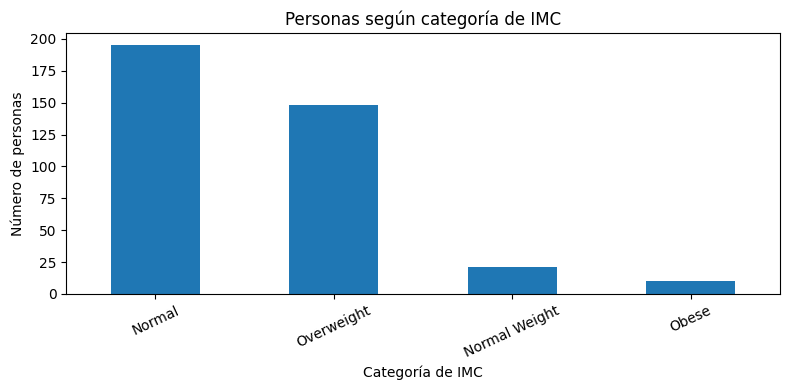

In [ ]:
import matplotlib.pyplot as plt
frecuencia_imc.plot(kind="bar", figsize=(8,4))
plt.title("Personas según categoría de IMC")
plt.xlabel("Categoría de IMC")
plt.ylabel("Número de personas")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## Nivel básico — Estadísticos descriptivos
### 2.7. Media, mediana y moda de la edad

- **Media:** suma de edades dividida por el número de personas.
- **Mediana:** edad que deja la mitad de observaciones a cada lado.
- **Moda:** edad más repetida.

Se calculan una variable a la vez.

In [ ]:
edad = salud["Age"]
print("Media de edad:", round(edad.mean(),2))
print("Mediana de edad:", edad.median())
print("Moda de edad:", edad.mode().tolist())

Media de edad: 42.18
Mediana de edad: 43.0
Moda de edad: [43]


### 2.8. Medidas de dispersión para la edad

El rango es la diferencia entre máximo y mínimo; la varianza y desviación estándar describen la dispersión, y el rango intercuartílico (RIC) mide la amplitud del 50 % central. Se utiliza la varianza **muestral** (`ddof=1`).

In [ ]:
print("Mínimo:", edad.min())
print("Máximo:", edad.max())
print("Rango:", edad.max()-edad.min())
print("Varianza muestral:", round(edad.var(),2))
print("Desviación estándar muestral:", round(edad.std(),2))
print("Q1:", edad.quantile(0.25))
print("Q3:", edad.quantile(0.75))
print("RIC:", edad.quantile(0.75)-edad.quantile(0.25))

Mínimo: 27
Máximo: 59
Rango: 32
Varianza muestral: 75.22
Desviación estándar muestral: 8.67
Q1: 35.25
Q3: 50.0
RIC: 14.75


### 2.9. Repetir las medidas para la duración del sueño

**Pregunta:** ¿cuál es la duración típica del sueño y cuánto cambia entre personas? Compare media y mediana, y observe su desviación estándar.

In [ ]:
sueno = salud["Sleep_Duration"]
print("Media:", round(sueno.mean(),2), "horas")
print("Mediana:", sueno.median(), "horas")
print("Moda:", sueno.mode().tolist())
print("Desviación estándar:", round(sueno.std(),2), "horas")
print("Mínimo y máximo:", sueno.min(), sueno.max())

Media: 7.13 horas
Mediana: 7.2 horas
Moda: [7.2]
Desviación estándar: 0.8 horas
Mínimo y máximo: 5.8 8.5


### 2.10. Tabla de resumen para tres variables

`describe()` resume tamaño, media, desviación estándar, mínimo, cuartiles y máximo. Los resultados corresponden a variables **numéricas seleccionadas**.

In [ ]:
display(salud[["Age", "Sleep_Duration", "Stress_Level"]].describe().round(2))

,Age,Sleep_Duration,Stress_Level
count,374.00,374.00,374.00
mean,42.18,7.13,5.39
std,8.67,0.80,1.77
min,27.00,5.80,3.00
25%,35.25,6.40,4.00
50%,43.00,7.20,5.00
75%,50.00,7.80,7.00
max,59.00,8.50,8.00


### 2.11. Histograma de duración del sueño

Un histograma agrupa valores numéricos en intervalos. Ayuda a identificar concentración y forma de la distribución.

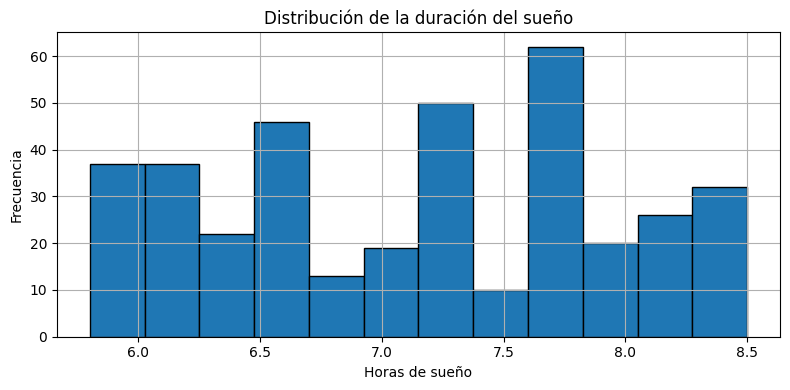

In [ ]:
salud["Sleep_Duration"].hist(bins=12, edgecolor="black", figsize=(8,4))
plt.title("Distribución de la duración del sueño")
plt.xlabel("Horas de sueño")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### 2.12. Diagrama de caja y valores atípicos

La caja va de Q1 a Q3 y la línea interna es la mediana. La regla de 1.5 × RIC identifica **posibles valores atípicos**, que no deben borrarse sin revisarlos.

Límites: 4.3 9.9
Posibles valores atípicos: 0


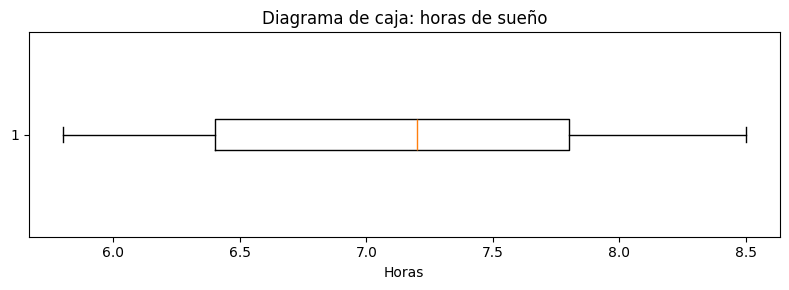

In [ ]:
q1 = sueno.quantile(0.25)
q3 = sueno.quantile(0.75)
ric = q3-q1
limite_inferior = q1-1.5*ric
limite_superior = q3+1.5*ric
atipicos = salud[(salud["Sleep_Duration"] < limite_inferior) |
                 (salud["Sleep_Duration"] > limite_superior)]
print("Límites:", round(limite_inferior,2), round(limite_superior,2))
print("Posibles valores atípicos:", len(atipicos))
plt.figure(figsize=(8,3))
plt.boxplot(sueno.dropna(), vert=False)
plt.title("Diagrama de caja: horas de sueño")
plt.xlabel("Horas")
plt.tight_layout()
plt.show()

## Nivel intermedio — Comparar grupos
### 2.13. Tabla de contingencia: género y categoría de IMC

`crosstab()` cuenta combinaciones de dos variables categóricas. No mide por sí sola asociación causal.

In [ ]:
tabla_cruzada = pd.crosstab(salud["Gender"], salud["BMI_Category"])
display(tabla_cruzada)
print("Porcentaje dentro de cada género:")
display((pd.crosstab(salud["Gender"], salud["BMI_Category"], normalize="index")*100).round(1))

BMI_Category,Normal,Normal Weight,Obese,Overweight
Gender,,,,
Female,64,14,1,106
Male,131,7,9,42


Porcentaje dentro de cada género:


BMI_Category,Normal,Normal Weight,Obese,Overweight
Gender,,,,
Female,34.6,7.6,0.5,57.3
Male,69.3,3.7,4.8,22.2


### 2.14. Barras apiladas por grupos

Se muestran porcentajes dentro de cada género para evitar confundir las diferencias de tamaño entre los grupos.

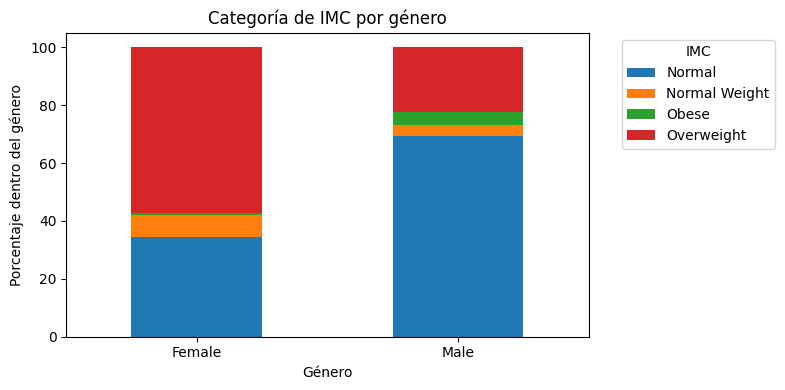

In [ ]:
porcentajes = pd.crosstab(salud["Gender"], salud["BMI_Category"], normalize="index")*100
porcentajes.plot(kind="bar", stacked=True, figsize=(8,4))
plt.title("Categoría de IMC por género")
plt.xlabel("Género")
plt.ylabel("Porcentaje dentro del género")
plt.xticks(rotation=0)
plt.legend(title="IMC", bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.show()

### 2.15. Comparar duración del sueño según género

`groupby()` permite calcular el tamaño de cada grupo y medidas descriptivas. Compare **media, mediana y dispersión**, sin concluir que el género causa diferencias de sueño.

In [ ]:
resumen_genero = salud.groupby("Gender")["Sleep_Duration"].agg(
    ["count", "mean", "median", "std", "min", "max"])
display(resumen_genero.round(2))

,count,mean,median,std,min,max
Gender,,,,,,
Female,185,7.23,7.2,0.88,5.8,8.5
Male,189,7.04,7.2,0.69,5.9,8.1


### 2.16. Diagramas de caja por género

Se comparan visualmente las medianas, la amplitud de las cajas y posibles valores atípicos de las horas de sueño.

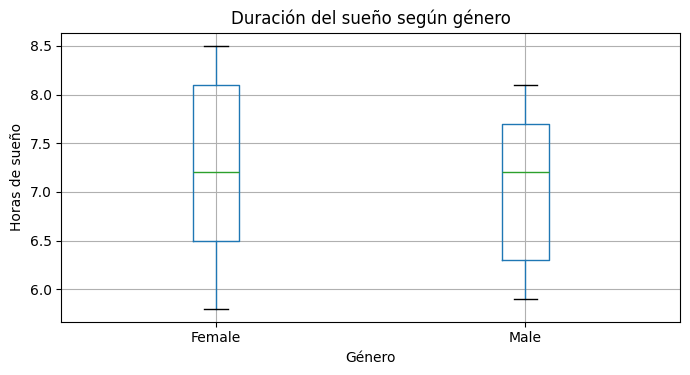

In [ ]:
salud.boxplot(column="Sleep_Duration", by="Gender", figsize=(7,4))
plt.suptitle("")
plt.title("Duración del sueño según género")
plt.xlabel("Género")
plt.ylabel("Horas de sueño")
plt.tight_layout()
plt.show()

### 2.17. Analizar el nivel de estrés según calidad del sueño

Se obtiene un promedio de estrés para cada puntuación de calidad del sueño. **No se interpreta como causa y efecto.**

,count,mean,median
Quality_of_Sleep,,,
4,5,8.00,8.0
5,7,7.00,7.0
6,105,7.58,8.0
7,77,5.35,6.0
8,109,4.61,5.0
9,71,3.03,3.0


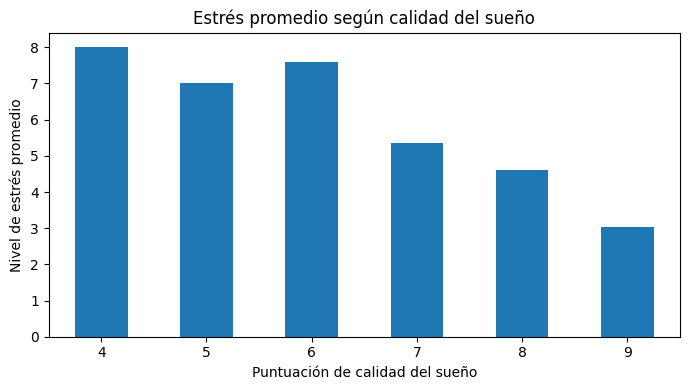

In [ ]:
estres_por_calidad = salud.groupby("Quality_of_Sleep")["Stress_Level"].agg(["count","mean","median"])
display(estres_por_calidad.round(2))
estres_por_calidad["mean"].plot(kind="bar", figsize=(7,4))
plt.title("Estrés promedio según calidad del sueño")
plt.xlabel("Puntuación de calidad del sueño")
plt.ylabel("Nivel de estrés promedio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.18. Trastornos del sueño y valores faltantes

El archivo tiene valores vacíos en `Sleep_Disorder`. Para describir las categorías se mostrará **No reportado**, sin convertirlo en un diagnóstico de ausencia de trastorno.

,Personas,Porcentaje (%)
Sleep_Disorder,,
No reportado,219,58.56
Sleep Apnea,78,20.86
Insomnia,77,20.59


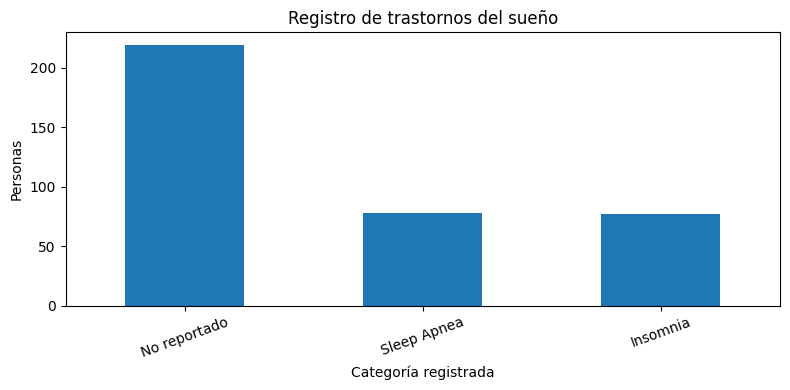

In [ ]:
trastorno = salud["Sleep_Disorder"].fillna("No reportado")
tabla_trastornos = pd.DataFrame({
    "Personas": trastorno.value_counts(),
    "Porcentaje (%)": (trastorno.value_counts(normalize=True)*100).round(2)
})
display(tabla_trastornos)
trastorno.value_counts().plot(kind="bar", figsize=(8,4))
plt.title("Registro de trastornos del sueño")
plt.xlabel("Categoría registrada")
plt.ylabel("Personas")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Nivel intermedio — Relaciones entre variables numéricas
### 2.19. Diagrama de dispersión: horas de sueño y estrés

Cada punto corresponde a una persona. Observe si existe una tendencia creciente, decreciente o ausencia de patrón claro.

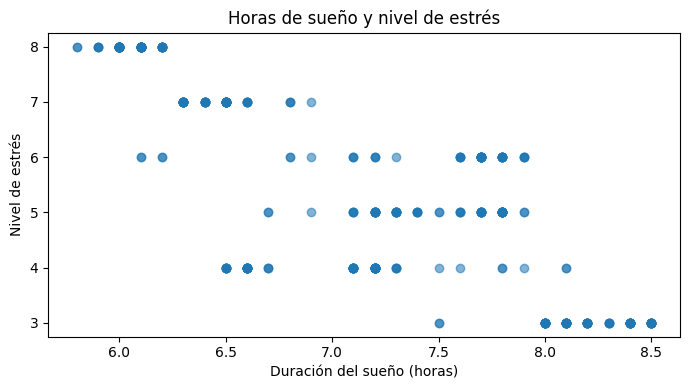

In [ ]:
plt.figure(figsize=(7,4))
plt.scatter(salud["Sleep_Duration"], salud["Stress_Level"], alpha=0.55)
plt.title("Horas de sueño y nivel de estrés")
plt.xlabel("Duración del sueño (horas)")
plt.ylabel("Nivel de estrés")
plt.tight_layout()
plt.show()

### 2.20. Coeficiente de correlación de Pearson

La correlación de Pearson está entre −1 y 1. Un valor negativo indica tendencia lineal decreciente, positivo indica creciente, y cercano a cero indica poca relación **lineal**. No implica causalidad. Como `Stress_Level` es una escala discreta, el resultado es una aproximación descriptiva.

In [ ]:
r = salud["Sleep_Duration"].corr(salud["Stress_Level"])
print("Correlación de Pearson entre sueño y estrés:", round(r,3))
if r < 0:
    print("La asociación lineal observada es negativa.")
elif r > 0:
    print("La asociación lineal observada es positiva.")
else:
    print("No hay correlación lineal observada.")

Correlación de Pearson entre sueño y estrés: -0.811
La asociación lineal observada es negativa.


### 2.21. Matriz de correlaciones

Se comparan variables numéricas relevantes, **excluyendo Person_ID** porque es solo un identificador. Una matriz de correlaciones resume asociaciones lineales por pares.

,Age,Sleep_Duration,Quality_of_Sleep,Physical_Activity_Level,Stress_Level,Heart_Rate,Daily_Steps
Age,1.00,0.34,0.47,0.18,-0.42,-0.23,0.06
Sleep_Duration,0.34,1.00,0.88,0.21,-0.81,-0.52,-0.04
Quality_of_Sleep,0.47,0.88,1.00,0.19,-0.90,-0.66,0.02
Physical_Activity_Level,0.18,0.21,0.19,1.00,-0.03,0.14,0.77
Stress_Level,-0.42,-0.81,-0.90,-0.03,1.00,0.67,0.19
Heart_Rate,-0.23,-0.52,-0.66,0.14,0.67,1.00,-0.03
Daily_Steps,0.06,-0.04,0.02,0.77,0.19,-0.03,1.00


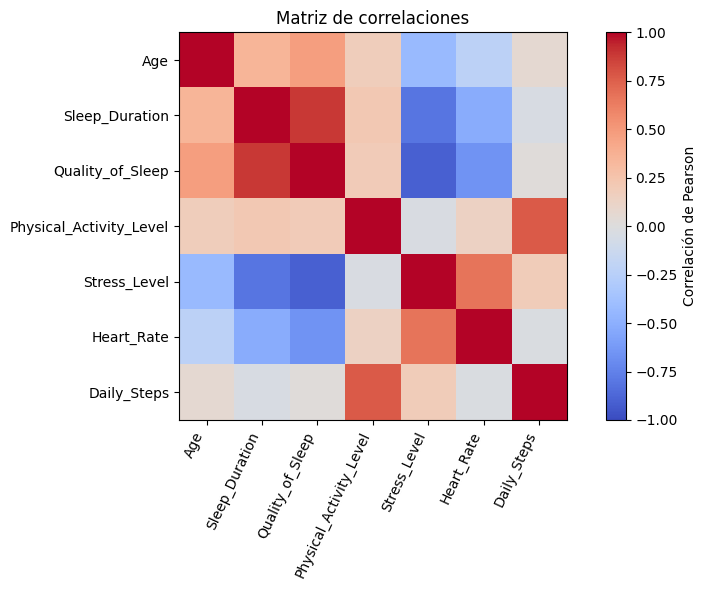

In [ ]:
numericas = ["Age", "Sleep_Duration", "Quality_of_Sleep",
             "Physical_Activity_Level", "Stress_Level", "Heart_Rate", "Daily_Steps"]
correlaciones = salud[numericas].corr()
display(correlaciones.round(2))
plt.figure(figsize=(9,6))
plt.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlación de Pearson")
plt.xticks(range(len(numericas)), numericas, rotation=65, ha="right")
plt.yticks(range(len(numericas)), numericas)
plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

### 2.22. Correlación de Spearman: una alternativa intermedia

Spearman se basa en rangos; describe asociaciones monótonas (no necesariamente lineales). Puede ser útil como complemento para puntuaciones ordinales de estrés y calidad del sueño.

In [ ]:
pearson = salud["Stress_Level"].corr(salud["Quality_of_Sleep"], method="pearson")
spearman = salud["Stress_Level"].corr(salud["Quality_of_Sleep"], method="spearman")
print("Pearson:", round(pearson,3))
print("Spearman:", round(spearman,3))
print("Compare signo y magnitud; ninguna correlación implica causalidad.")

Pearson: -0.899
Spearman: -0.908
Compare signo y magnitud; ninguna correlación implica causalidad.


### 2.23. Tabla dinámica por género y categoría de IMC

Una tabla dinámica (`pivot_table`) resume simultáneamente dos agrupaciones. `observed=True` evita combinaciones de categorías que no aparezcan.

In [ ]:
tabla_dinamica = salud.pivot_table(values="Sleep_Duration",
                                   index="Gender", columns="BMI_Category",
                                   aggfunc="mean", observed=True)
display(tabla_dinamica.round(2))

BMI_Category,Normal,Normal Weight,Obese,Overweight
Gender,,,,
Female,7.79,7.29,7.40,6.88
Male,7.20,7.43,6.91,6.49


### 2.24. Conclusiones con resultados de la base

Este bloque produce frases usando cálculos obtenidos del CSV, evitando inventar conclusiones. **La interpretación final requiere comparar también distribuciones y tamaños de los grupos.**

In [ ]:
print("Registros analizados:", len(salud))
print("Media de edad:", round(salud["Age"].mean(),2), "años")
print("Duración media del sueño:", round(salud["Sleep_Duration"].mean(),2), "horas")
print("Mediana de estrés:", salud["Stress_Level"].median())
print("Categoría de IMC más frecuente:", salud["BMI_Category"].mode()[0])
print("Sin registro en Sleep_Disorder:", salud["Sleep_Disorder"].isna().sum())
print("Correlación sueño-estrés:", round(salud["Sleep_Duration"].corr(salud["Stress_Level"]),3))

Registros analizados: 374
Media de edad: 42.18 años
Duración media del sueño: 7.13 horas
Mediana de estrés: 5.0
Categoría de IMC más frecuente: Normal
Sin registro en Sleep_Disorder: 219
Correlación sueño-estrés: -0.811


## Actividad práctica de interpretación

Responda a partir de las tablas y gráficas ejecutadas:

1. ¿Qué diferencia hay entre número de registros y número de variables?
2. ¿Por qué no se debe calcular el promedio de `Person_ID`?
3. ¿Cuál es la categoría de IMC más frecuente y qué porcentaje representa?
4. ¿La edad presenta mucha o poca dispersión? Justifique con la desviación estándar y el rango.
5. ¿Qué indica la diferencia entre media y mediana de las horas de sueño?
6. ¿Qué información aporta el histograma que no ofrece la media?
7. ¿Existen posibles valores atípicos de sueño según el RIC? ¿Deben eliminarse automáticamente?
8. ¿La distribución de IMC es igual entre los géneros? Compare los porcentajes por fila.
9. ¿Qué asociación se observa entre horas de sueño y nivel de estrés? Sustente con el gráfico y Pearson.
10. ¿Por qué no se pueden atribuir relaciones causales a una correlación?
11. ¿Por qué no se deben sustituir los 219 registros faltantes de `Sleep_Disorder` por «sin trastorno»?
12. Compare las correlaciones Pearson y Spearman para estrés y calidad del sueño.

**Producto esperado:** breve informe con tres tablas, tres gráficos y cinco conclusiones respaldadas por cifras.